# EPL accuracy versus calibration: first experiment

This notebook loads the completed, reproducible experiment. It does not retrain or select models using the test season. See `METHODOLOGY.md` and `results/RESULTS.md` for corrected literature, timing limitations and interpretation.

Reproduce from the repository root: `python -m epl_modeling.experiment --trials 12`.

In [1]:
from pathlib import Path
import json
import pandas as pd
from IPython.display import display, Image
here = Path.cwd()
RESULTS = here / 'results' if (here / 'results/run_metadata.json').exists() else here / 'epl_modeling/results'
metadata = json.loads((RESULTS / 'run_metadata.json').read_text())
print('Snapshot:', metadata['data_snapshot_as_of'])
print('Locked winners:', metadata['frozen_choices']['families'])
display(pd.read_parquet(RESULTS / 'chronological_splits.parquet'))

Snapshot: 2026-10-06
Locked winners: {'accuracy': 'svm', 'calibration': 'mlp'}


,split,seasons,n_matches,date_min,date_max,H,D,A
0,train,"2014-15,2015-16,2016-17,2017-18,2018-19,2019-2...",2250,2014-08-16,2021-05-23,1001,524,725
1,tune,2021-22,338,2021-08-13,2022-05-22,146,76,116
2,calibration,2022-23,368,2022-08-05,2023-05-28,177,86,105
3,model_selection,2023-24,360,2023-08-11,2024-05-19,167,77,116
4,strategy_validation,2024-25,368,2024-08-16,2025-05-25,148,92,128
5,test,2025-26,374,2025-08-15,2026-05-24,159,103,112
6,monitoring,2026-27,50,2026-08-21,2026-09-20,18,16,16


## Held-out probability quality
Lower log loss, Brier and ECE are better. ECE alone can favor uninformative forecasts.

,model,family,split,scope,n_matches,accuracy,classwise_ece_10,classwise_ece_5,classwise_ece_15,log_loss,brier_score
0,accuracy,svm,test,all_cohort_matches,374,0.481283,0.062007,0.061256,0.061256,1.076337,0.644606
1,accuracy,svm,test,matched_bookmaker_coverage,374,0.481283,0.062007,0.061256,0.061256,1.076337,0.644606
2,calibration,mlp,test,all_cohort_matches,374,0.443850,0.041569,0.033122,0.049476,1.056392,0.635617
3,calibration,mlp,test,matched_bookmaker_coverage,374,0.443850,0.041569,0.033122,0.049476,1.056392,0.635617
4,training_class_frequency,baseline,test,all_cohort_matches,374,0.425134,0.029041,0.029041,0.029041,1.085117,0.656610
5,bet365_devig,market_baseline,test,matched_bookmaker_coverage,374,0.486631,0.043554,0.035766,0.047691,1.019061,0.612015
6,training_class_frequency,baseline,test,matched_bookmaker_coverage,374,0.425134,0.029041,0.029041,0.029041,1.085117,0.656610


,metric,difference_calibration_minus_accuracy,ci_lower,ci_upper,bootstrap_unit,n_bootstrap
0,accuracy,-0.037433,-0.070925,-0.002731,match_calendar_date,1000
1,classwise_ece_10,-0.020438,-0.043677,0.006777,match_calendar_date,1000
2,log_loss,-0.019945,-0.045120,0.005764,match_calendar_date,1000
3,brier_score,-0.008990,-0.025229,0.007619,match_calendar_date,1000


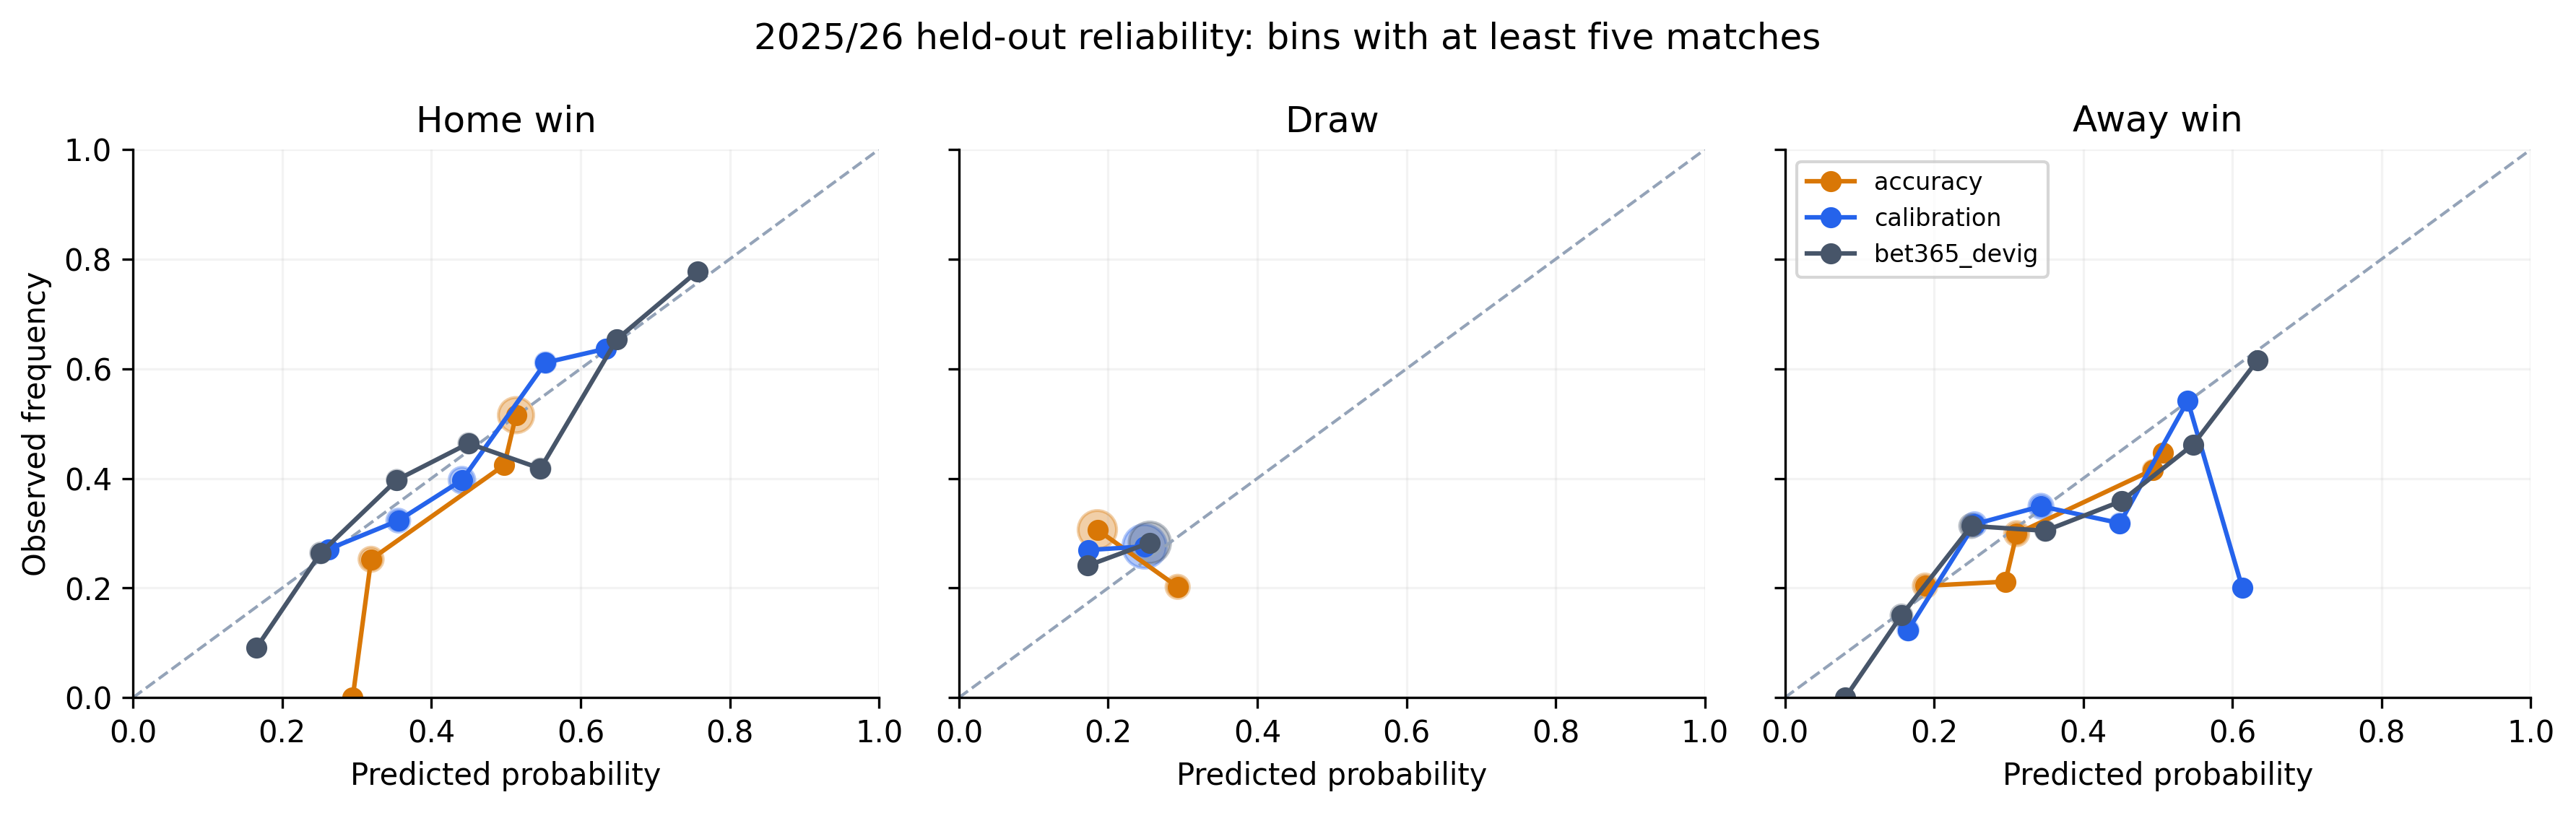

In [2]:
scores = pd.read_parquet(RESULTS / 'classification_scores.parquet')
display(scores[scores['split'].eq('test')].reset_index(drop=True))
display(pd.read_parquet(RESULTS / 'paired_test_metric_intervals.parquet'))
display(Image(filename=str(RESULTS / 'test_reliability.png')))

## Archived-price replay
Thresholds were selected only on 2024/25. The 5% policy is a separately predeclared secondary comparison. ROI is profit / stakes, not return on initial bankroll. Quote simultaneity, limits, availability times and execution are unverified.

,branch,policy,odds_mode,staking,bet_count,profit,turnover,roi,roi_ci_low,roi_ci_high,max_drawdown
0,accuracy,validation_selected,best_individual_book,fixed,0,0.000000,0.000000,NaN,NaN,NaN,0.000000
1,accuracy,validation_selected,best_individual_book,kelly,0,0.000000,0.000000,NaN,NaN,NaN,0.000000
2,accuracy,validation_selected,bet365_reference,fixed,0,0.000000,0.000000,NaN,NaN,NaN,0.000000
3,accuracy,validation_selected,bet365_reference,kelly,0,0.000000,0.000000,NaN,NaN,NaN,0.000000
4,accuracy,predeclared_5pct,best_individual_book,fixed,371,-83.300000,3710.000000,-0.022453,-0.188338,0.154476,0.277397
5,accuracy,predeclared_5pct,best_individual_book,kelly,371,-377.049582,5376.771019,-0.070126,-0.231832,0.119249,0.499503
6,accuracy,predeclared_5pct,bet365_reference,fixed,365,-186.700000,3650.000000,-0.051151,-0.202468,0.111493,0.286032
7,accuracy,predeclared_5pct,bet365_reference,kelly,365,-433.140757,5055.800429,-0.085672,-0.236427,0.087942,0.512128
8,calibration,validation_selected,best_individual_book,fixed,0,0.000000,0.000000,NaN,NaN,NaN,0.000000
9,calibration,validation_selected,best_individual_book,kelly,0,0.000000,0.000000,NaN,NaN,NaN,0.000000


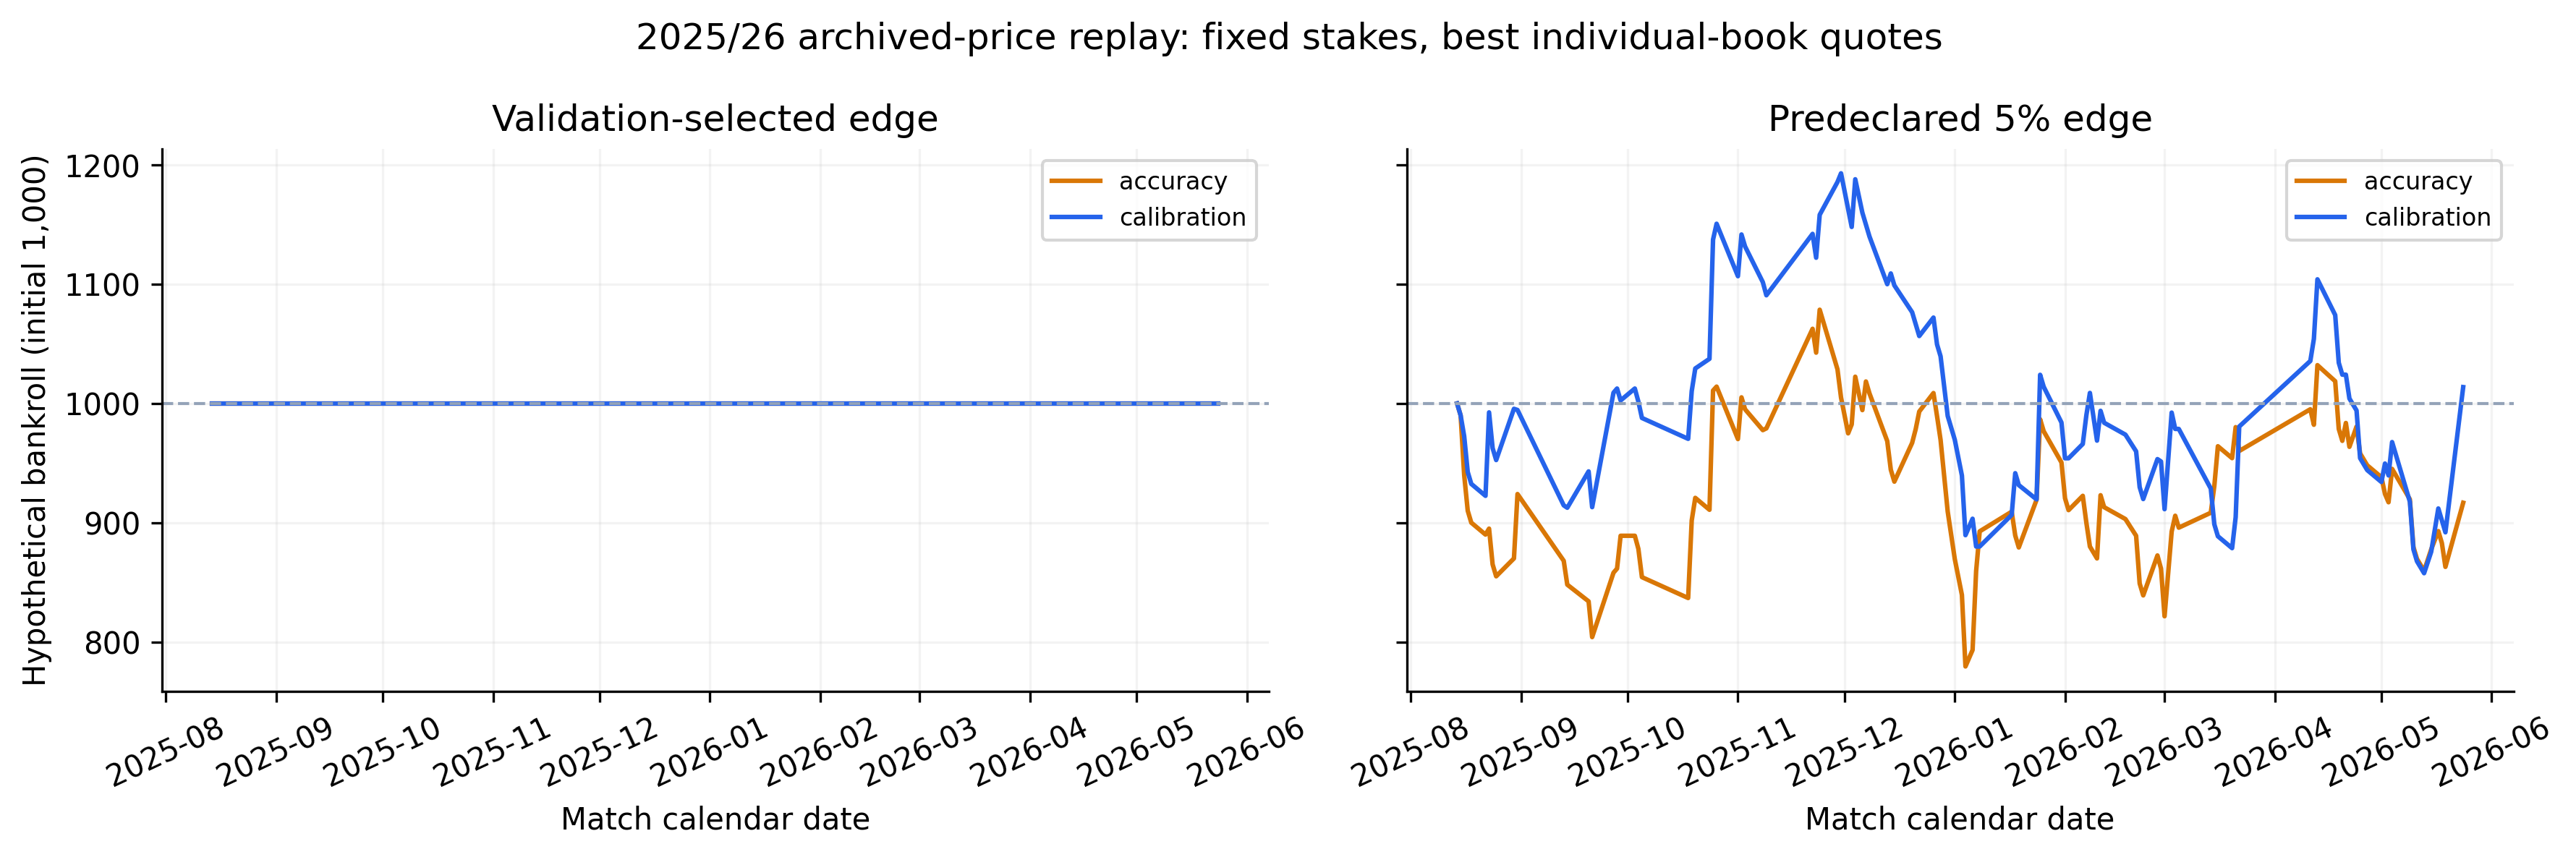

In [3]:
betting = pd.read_parquet(RESULTS / 'betting_summary.parquet')
columns = ['branch','policy','odds_mode','staking','bet_count','profit','turnover','roi','roi_ci_low','roi_ci_high','max_drawdown']
display(betting[betting['split'].eq('test')][columns].reset_index(drop=True))
display(Image(filename=str(RESULTS / 'test_bankroll.png')))

## Player and team feature audit
Only strictly earlier match observations can enter predictors; current squads, injuries and final-season totals are excluded.

In [4]:
display(json.loads((RESULTS / 'selected_features.json').read_text()))
filters = pd.read_parquet(RESULTS / 'feature_filter_audit.parquet')
display(filters[['feature','train_missing_rate','ks_statistic','ks_qvalue','drop_reason']].head(25))
features = json.loads((RESULTS / 'feature_metadata.json').read_text())
print('Feature metadata keys:', list(features))

{'accuracy': ['feat_diff_std_corners_diff',
  'feat_diff_roll10_shots_on_target_diff'],
 'calibration': ['feat_diff_std_corners_against']}

,feature,train_missing_rate,ks_statistic,ks_qvalue,drop_reason
0,feat_home_history_matches,0.000000,0.406491,3.096167e-81,early_late_training_distribution_shift
1,feat_home_rest_days,0.000889,0.101242,1.454140e-04,
2,feat_home_fd_history_missing,0.000000,0.000273,1.000000e+00,
3,feat_home_roll5_points,0.000889,0.026313,9.966407e-01,spearman_redundancy
4,feat_home_roll5_win,0.000889,0.026313,9.966407e-01,
5,feat_home_roll5_goals_for,0.000889,0.032014,8.400390e-01,
6,feat_home_roll5_goals_against,0.000889,0.030072,8.895855e-01,
7,feat_home_roll5_goals_diff,0.000889,0.033300,7.918504e-01,
8,feat_home_roll5_shots_for,0.000889,0.071167,2.688862e-02,
9,feat_home_roll5_shots_against,0.000889,0.072513,2.269857e-02,


Feature metadata keys: ['rows', 'feature_count', 'feature_columns', 'feature_definitions', 'coverage', 'history_scope', 'leakage_checks', 'limitations']


## Mathematical price discrepancies
These are archived-price candidates, not verified executable arbitrage.

In [5]:
odds = pd.read_parquet(RESULTS / 'bookmaker_odds_panel.parquet')
test_odds = odds[odds['season'].eq('2025-26')]
print('Test matches with odds:', len(test_odds))
print('Mathematical candidates:', int(test_odds['mathematical_arb_candidate'].sum()))
print('Unverified quote clocks:', int(test_odds['quotes_asynchronous_or_unverified'].sum()))
display(test_odds[test_odds['mathematical_arb_candidate']][['match_id','match_date','arb_inverse_odds_sum','arb_theoretical_margin']].head(10))

Test matches with odds: 374
Mathematical candidates: 0
Unverified quote clocks: 374


,match_id,match_date,arb_inverse_odds_sum,arb_theoretical_margin
